# ARTI 403 Image Processing
## Lab 8: Edge Detection

Name: Mohammed Saeed Alamodi
ID: 2240009007

I used the butterfly image (Butterfly.jpg) instead of the kid image from the lab notebook.

## Task 1: Apply Edge Detection Methods

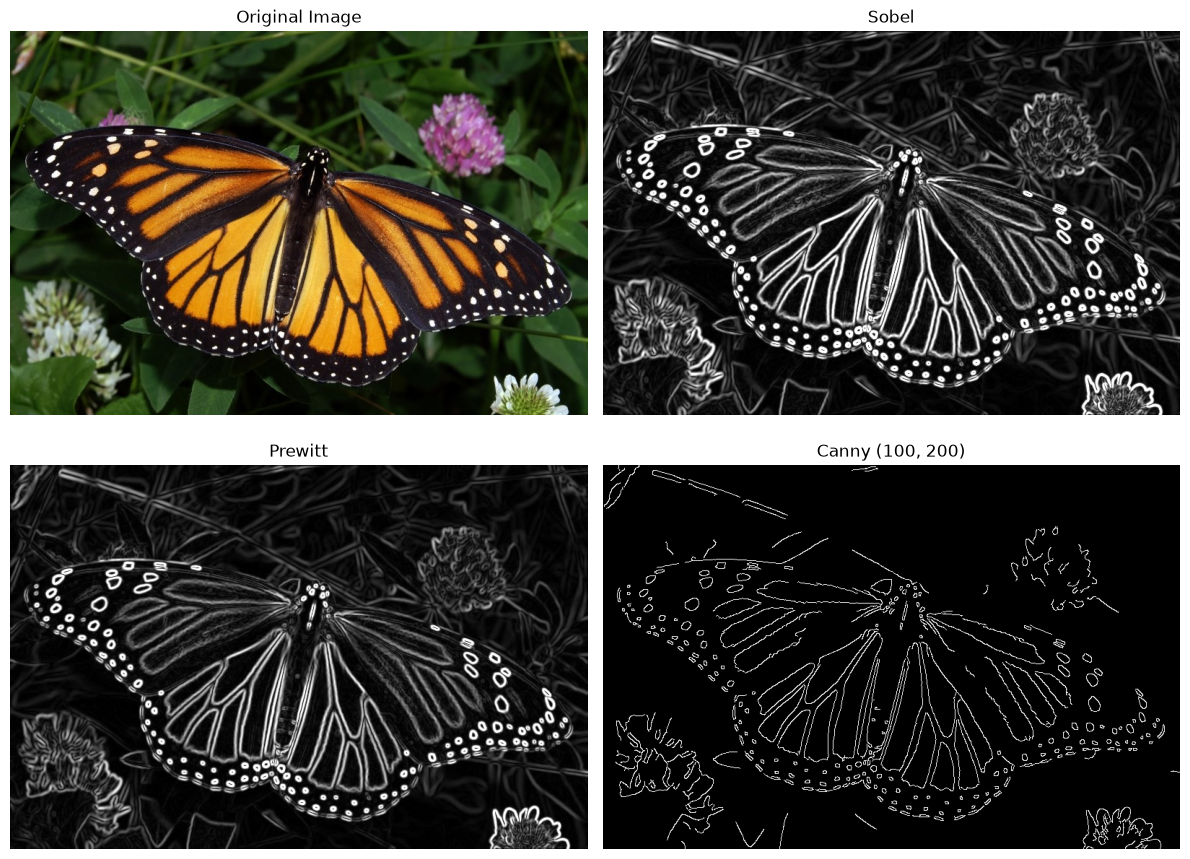

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('Butterfly.jpg')
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

# Sobel
sobelx = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)
sobel_final = np.uint8(np.clip(cv2.magnitude(sobelx, sobely), 0, 255))

# Prewitt (kernels defined by hand)
kernel_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float64)
kernel_y = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float64)
prewitt_x = cv2.filter2D(blurred, cv2.CV_64F, kernel_x)
prewitt_y = cv2.filter2D(blurred, cv2.CV_64F, kernel_y)
prewitt_final = np.uint8(np.clip(cv2.magnitude(prewitt_x, prewitt_y), 0, 255))

# Canny
canny_edges = cv2.Canny(blurred, 100, 200)

fig, ax = plt.subplots(2, 2, figsize=(12, 9))
ax[0, 0].imshow(rgb);                         ax[0, 0].set_title('Original Image')
ax[0, 1].imshow(sobel_final, cmap='gray');    ax[0, 1].set_title('Sobel')
ax[1, 0].imshow(prewitt_final, cmap='gray');  ax[1, 0].set_title('Prewitt')
ax[1, 1].imshow(canny_edges, cmap='gray');    ax[1, 1].set_title('Canny (100, 200)')
for a in ax.ravel():
    a.axis('off')
plt.tight_layout()
plt.show()

Sobel and Prewitt give thick, grayscale edge maps that look almost the same. They show the wing veins and the white dots well, but they also pick up a lot of the grass and flower texture in the background. Canny gives thin, clean one pixel lines, so the wing outline and veins are easier to follow.

## Task 2: Effect of the Canny Thresholds

Low = 30, High = 90: 33792 edge pixels
Low = 50, High = 150: 23434 edge pixels
Low = 100, High = 200: 16823 edge pixels


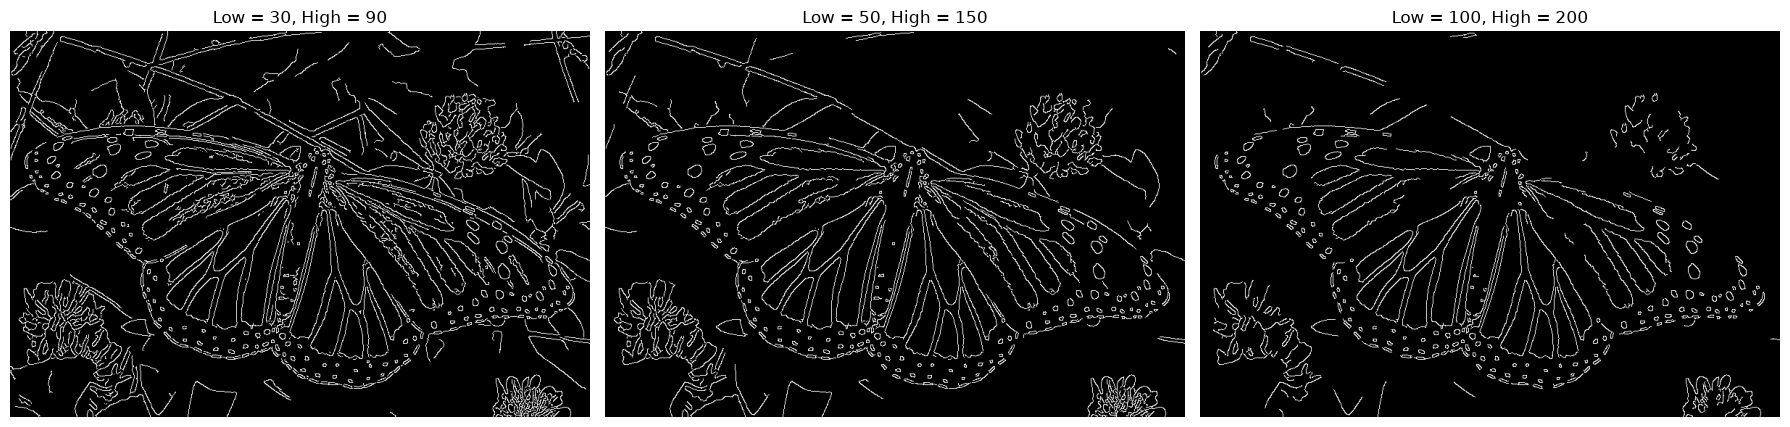

In [2]:
pairs = [(30, 90), (50, 150), (100, 200)]

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
for a, (low, high) in zip(ax, pairs):
    edges = cv2.Canny(blurred, low, high)
    a.imshow(edges, cmap='gray')
    a.set_title(f'Low = {low}, High = {high}')
    a.axis('off')
    print(f'Low = {low}, High = {high}: {np.count_nonzero(edges)} edge pixels')
plt.tight_layout()
plt.show()

Lowering the thresholds gives more edges: 33,792 edge pixels for (30, 90), 23,434 for (50, 150) and 16,823 for (100, 200). With low thresholds the weak details show up, like the fine lines inside the wings and the grass stems and flower petals in the background, but there is more clutter. With (100, 200) only the strong edges stay, so the butterfly is clearer and the background is mostly gone, but some small dots and weak lines on the wings are lost.